# 03 - Is the model a good fit?

Five ways to judge the served HistGradientBoosting model (`artifacts/model.skops`, trained on all
2.67 million training rows) beyond one RMSE. Sections 1-3 retrain on the 500,000-row sample to
compare like with like and to draw the learning curve.

1. **Train vs validation error**: a large gap means overfitting, two high errors mean underfitting.
2. **Learning curve**: does more data still help?
3. **Cross-validation**: is the score stable across different splits?
4. **Residuals**: are errors centred on zero, and where are they large?
5. **Out-of-time**: does it hold up on February 2025?

In [1]:
import os
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from src import data, model_io
from src.compare import make_model
from src.features import FEATURES, build_features
from src.train import load_split

X_train, X_val, y_train, y_val, _ = load_split(500_000)
model = model_io.load()
print(model_io.load_metadata())
rmse = lambda y, p: root_mean_squared_error(y, p)

{'run_id': '59ac6cdd14eb495cb710e2fef2528726', 'run_name': 'compare-hgb-all', 'train_rows': 2671267, 'rmse': 3.700094318552444, 'mae': 2.4833793836533524, 'feb_rmse': 3.878756993135594, 'features': ['PULocationID', 'DOLocationID', 'trip_distance', 'pickup_hour', 'pickup_weekday']}


## 1. Train vs validation error (over- or underfitting)

In [2]:
rows = []
for name in ["linear", "rf", "hgb"]:
    m = make_model(name).fit(X_train, y_train)
    rows.append({"model": name, "train RMSE": rmse(y_train, m.predict(X_train)),
                 "validation RMSE": rmse(y_val, m.predict(X_val))})
gap = pd.DataFrame(rows).set_index("model")
gap["gap"] = gap["validation RMSE"] - gap["train RMSE"]
full_train_rmse = rmse(y_train, model.predict(X_train))
gap.loc["hgb (served, all rows)"] = [full_train_rmse, rmse(y_val, model.predict(X_val)), rmse(y_val, model.predict(X_val)) - full_train_rmse]
gap.round(3)

,train RMSE,validation RMSE,gap
model,,,
linear,5.434,5.473,0.039
rf,3.622,4.103,0.481
hgb,3.530,3.784,0.254
"hgb (served, all rows)",3.634,3.700,0.066


A forest fits its own training data much better than new data (a large gap: it partly memorises),
while boosting has a smaller gap, and almost none when trained on all rows. The linear model has similar train and validation errors that are
both high: it underfits.

## 2. Learning curve

,train rows,train RMSE,validation RMSE
0,25000,3.414,4.216
1,50000,3.308,4.076
2,100000,3.455,3.969
3,250000,3.481,3.847
4,500000,3.530,3.784


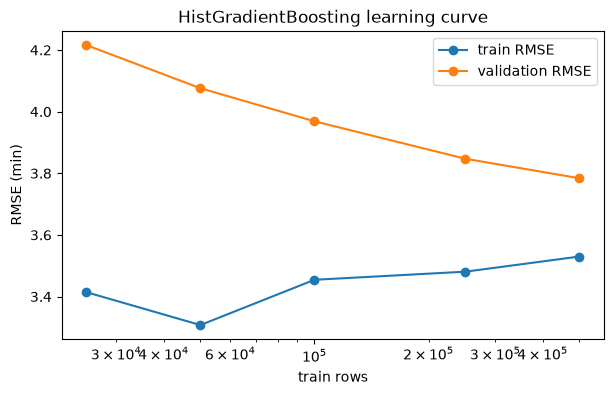

In [3]:
sizes = [25_000, 50_000, 100_000, 250_000, 500_000]  # the served model uses 2,671,267 (RMSE 3.70)
curve = []
for n in sizes:
    Xs = X_train.iloc[:n]; ys = y_train.iloc[:n]
    m = make_model("hgb").fit(Xs, ys)
    curve.append({"train rows": n, "train RMSE": rmse(ys, m.predict(Xs)), "validation RMSE": rmse(y_val, m.predict(X_val))})
curve = pd.DataFrame(curve)
ax = curve.plot(x="train rows", y=["train RMSE", "validation RMSE"], marker="o", logx=True, figsize=(7, 4))
ax.set_title("HistGradientBoosting learning curve"); ax.set_ylabel("RMSE (min)")
curve.round(3)

## 3. Cross-validation stability (5 folds on 200,000 training rows)

In [4]:
scores = -cross_val_score(make_model("hgb"), X_train.iloc[:200_000], y_train.iloc[:200_000],
                          cv=KFold(5, shuffle=True, random_state=42), scoring="neg_root_mean_squared_error", n_jobs=1)
print("fold RMSEs:", scores.round(3))
print(f"mean {scores.mean():.3f} ± {scores.std():.3f} min")

fold RMSEs: [3.982 3.936 3.909 3.889 3.897]
mean 3.923 ± 0.034 min


## 4. Residuals: where is the model wrong?

validation RMSE 3.700, MAE 2.483, mean error +0.001 min
within 2 min: 56.4%   within 5 min: 88.2%


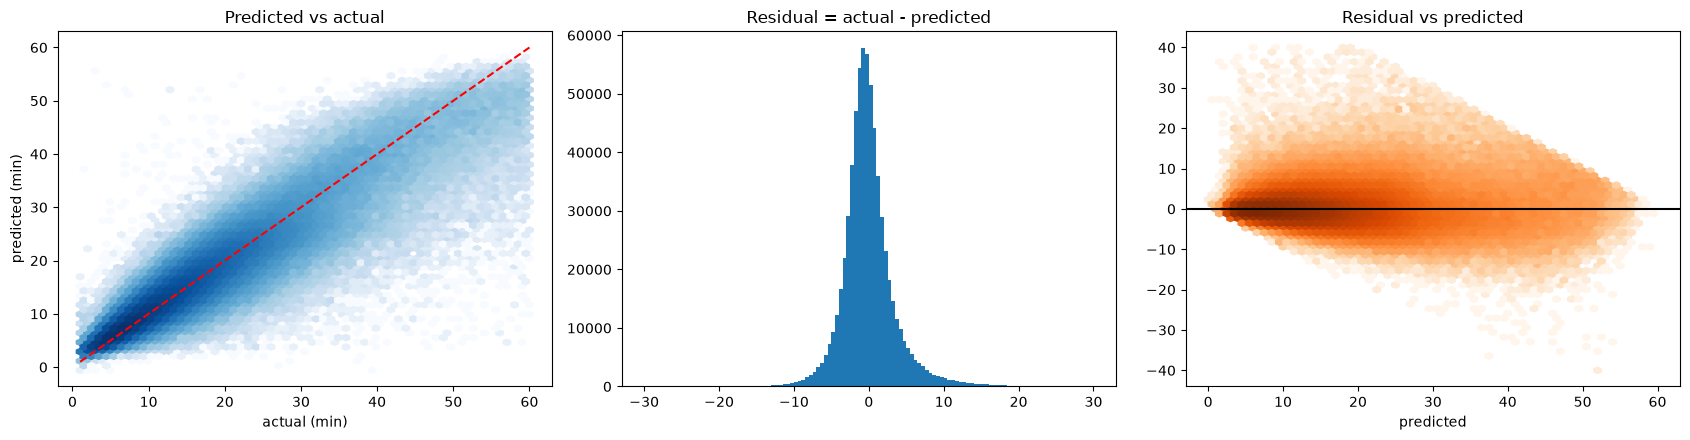

In [5]:
pred = model.predict(X_val)
res = y_val.to_numpy() - pred
print(f"validation RMSE {rmse(y_val, pred):.3f}, MAE {mean_absolute_error(y_val, pred):.3f}, mean error {res.mean():+.3f} min")
print(f"within 2 min: {(np.abs(res) <= 2).mean():.1%}   within 5 min: {(np.abs(res) <= 5).mean():.1%}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hexbin(y_val, pred, gridsize=60, bins="log", cmap="Blues"); axes[0].plot([1, 60], [1, 60], "r--")
axes[0].set_xlabel("actual (min)"); axes[0].set_ylabel("predicted (min)"); axes[0].set_title("Predicted vs actual")
axes[1].hist(res, bins=120, range=(-30, 30)); axes[1].set_title("Residual = actual - predicted")
axes[2].hexbin(pred, res, gridsize=60, bins="log", cmap="Oranges", extent=(0, 60, -40, 40))
axes[2].axhline(0, color="k"); axes[2].set_xlabel("predicted"); axes[2].set_title("Residual vs predicted")
plt.tight_layout()

In [6]:
seg = X_val.assign(actual=y_val.to_numpy(), pred=pred, abs_err=np.abs(res))
seg["duration band"] = pd.cut(seg.actual, [0, 5, 10, 20, 30, 45, 60])
seg["distance band"] = pd.cut(seg.trip_distance, [0, 1, 2, 5, 10, 20, 100])
seg["airport trip"] = seg.PULocationID.isin([1, 132, 138]) | seg.DOLocationID.isin([1, 132, 138])
by = lambda col: seg.groupby(col, observed=True).agg(trips=("abs_err", "size"), MAE=("abs_err", "mean"),
                                                     mean_actual=("actual", "mean"), mean_pred=("pred", "mean")).round(2)
display(by("duration band")); display(by("distance band")); display(by("airport trip"))

,trips,MAE,mean_actual,mean_pred
duration band,,,,
"(0, 5]",74155,1.43,3.66,4.93
"(5, 10]",199105,1.58,7.53,8.34
"(10, 20]",258269,2.34,14.24,14.44
"(20, 30]",87144,3.70,24.05,22.83
"(30, 45]",36976,5.59,35.92,33.08
"(45, 60]",12168,8.59,51.42,43.44


,trips,MAE,mean_actual,mean_pred
distance band,,,,
"(0, 1]",164150,1.60,6.20,6.20
"(1, 2]",224399,2.02,10.66,10.66
"(2, 5]",180205,2.85,17.37,17.36
"(5, 10]",57388,4.06,24.66,24.65
"(10, 20]",37233,4.71,36.28,36.31
"(20, 100]",4442,4.97,43.63,43.63


,trips,MAE,mean_actual,mean_pred
airport trip,,,,
False,613963,2.35,12.71,12.70
True,53854,4.01,31.46,31.52


Short trips are predicted well; the longest trips (45-60 minutes) are underpredicted on
average, because heavy traffic and waiting time are not in the features. That is the main
direction for improvement (route speed by hour, weather, traffic).

Text(0, 0.5, 'MAE (min)')

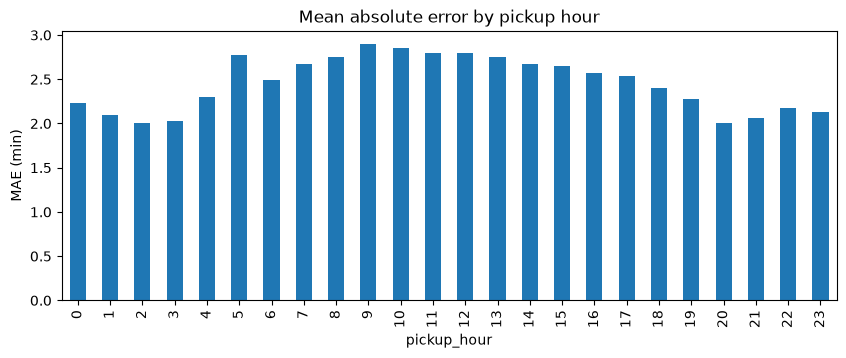

In [7]:
hourly = seg.groupby("pickup_hour").abs_err.mean()
ax = hourly.plot.bar(figsize=(10, 3.5), title="Mean absolute error by pickup hour"); ax.set_ylabel("MAE (min)")

## Which features matter? (permutation importance on 50,000 validation trips)

In [8]:
from sklearn.inspection import permutation_importance
sample = X_val.sample(50_000, random_state=0)
imp = permutation_importance(model, sample, y_val.loc[sample.index], n_repeats=3, random_state=0,
                             scoring="neg_root_mean_squared_error")
pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False).round(3).rename("RMSE increase when shuffled (min)")

trip_distance     10.145
pickup_hour        1.392
DOLocationID       0.974
PULocationID       0.881
pickup_weekday     0.556
Name: RMSE increase when shuffled (min), dtype: float64

## 5. Out-of-time: February 2025

In [9]:
feb = data.clean(data.load(data.download(2025, 2)), year=2025, month=2)
fp = model.predict(build_features(feb))
print(f"January validation RMSE {rmse(y_val, pred):.3f} | February RMSE {rmse(feb[data.TARGET], fp):.3f} "
      f"| February MAE {mean_absolute_error(feb[data.TARGET], fp):.3f}")

January validation RMSE 3.700 | February RMSE 3.879 | February MAE 2.568


## Verdict

The model is a **good fit**: small train/validation gap (no strong overfitting), validation error far
below the simple baselines, a stable score across folds, residuals centred near zero, and only a
small loss on the next month. Its weakness is long trips, which need traffic-related features.